# Pothole Detection using CNN 🚗
Convolutional Neural Network (CNN) implementation for detecting potholes in road images.

### Step 1: Importing Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

print(f"TensorFlow Version: {tf.__version__}")

# Check dataset directory structure
dataset_path = 'pothole-detection-dataset'
for root, dirs, files in os.walk(dataset_path):
    if files:
        print(f"{root}: {len(files)} files")

TensorFlow Version: 2.21.0
pothole-detection-dataset: 2 files
pothole-detection-dataset\normal: 352 files
pothole-detection-dataset\potholes: 329 files


### Step 2: Visualizing Sample Images

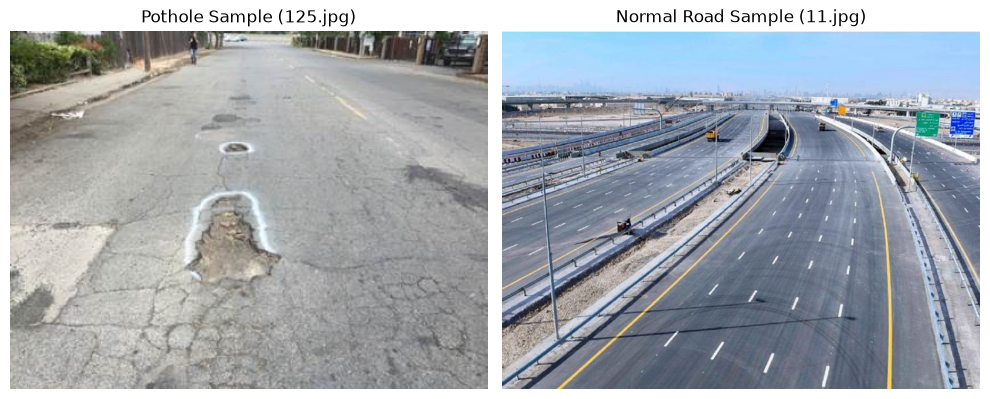

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

pothole_sample = cv2.imread('pothole-detection-dataset/potholes/125.jpg')
if pothole_sample is not None:
    axes[0].imshow(cv2.cvtColor(pothole_sample, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Pothole Sample (125.jpg)")
    axes[0].axis('off')

normal_sample = cv2.imread('pothole-detection-dataset/normal/11.jpg')
if normal_sample is not None:
    axes[1].imshow(cv2.cvtColor(normal_sample, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Normal Road Sample (11.jpg)")
    axes[1].axis('off')

plt.tight_layout()
plt.show()

### Step 3: Data Preprocessing & Augmentation

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

training_set = train_datagen.flow_from_directory(
    'pothole-detection-dataset',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    'pothole-detection-dataset',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

print(f"Class indices mapping: {training_set.class_indices}")

Found 546 images belonging to 2 classes.


Found 135 images belonging to 2 classes.


Class indices mapping: {'normal': 0, 'potholes': 1}


### Step 4: Building the CNN Model

In [4]:
cnn = tf.keras.models.Sequential([
    # Step 1 - First Convolutional Layer & Pooling
    tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]),
    tf.keras.layers.MaxPool2D(pool_size=2, strides=2),
    
    # Step 2 - Second Convolutional Layer & Pooling
    tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=2, strides=2),
    
    # Step 3 - Flattening & Fully Connected Layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=128, activation='relu'),
    tf.keras.layers.Dense(units=1, activation='sigmoid')
])

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

C:\Users\Akshit\OneDrive\Documents\TERM 7\DL\miniproj\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Training the CNN

In [5]:
epochs = 20
history = cnn.fit(
    x=training_set,
    validation_data=validation_generator,
    epochs=epochs
)

Epoch 1/20


 1/18 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.4062 - loss: 0.6969

 2/18 ━━━━━━━━━━━━━━━━━━━━ 6s 437ms/step - accuracy: 0.5312 - loss: 0.8173

 3/18 ━━━━━━━━━━━━━━━━━━━━ 9s 608ms/step - accuracy: 0.5417 - loss: 0.7880

 5/18 ━━━━━━━━━━━━━━━━━━━━ 6s 494ms/step - accuracy: 0.5154 - loss: 0.7729

...

15/18 ━━━━━━━━━━━━━━━━━━━━ 1s 351ms/step - accuracy: 0.9311 - loss: 0.1579

16/18 ━━━━━━━━━━━━━━━━━━━━ 0s 351ms/step - accuracy: 0.9295 - loss: 0.1617

17/18 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.9280 - loss: 0.1690

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.9304 - loss: 0.1638

18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 412ms/step - accuracy: 0.9304 - loss: 0.1638 - val_accuracy: 0.8444 - val_loss: 0.3445


### Step 6: Training & Validation Metrics Plot

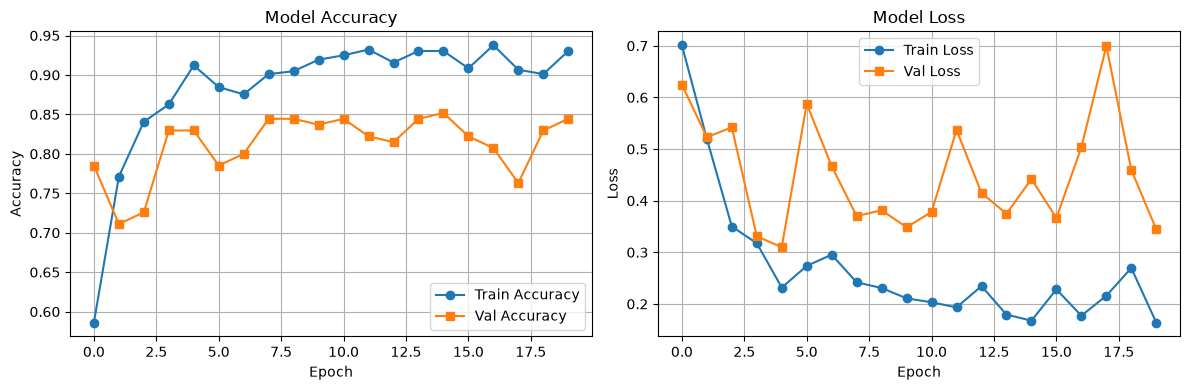

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='s')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='s')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Step 7: Making Predictions on Test Images

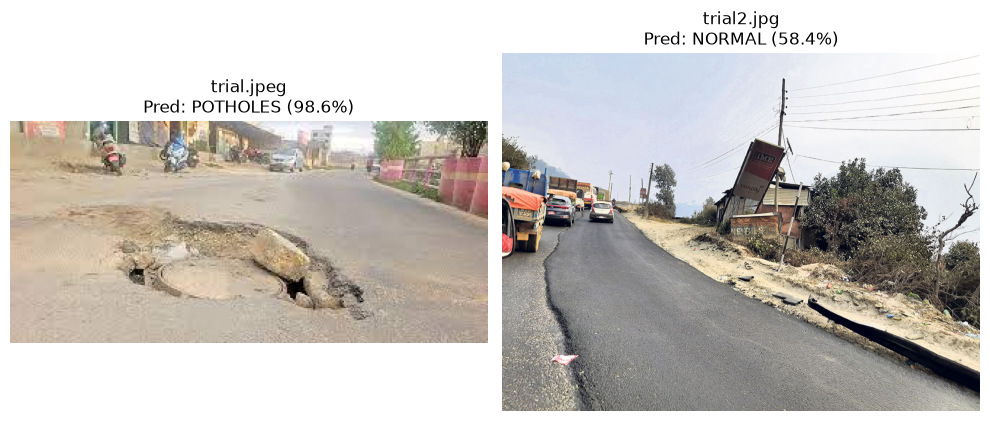

In [7]:
idx_to_label = {v: k for k, v in training_set.class_indices.items()}
test_images = ['pothole-detection-dataset/trial.jpeg', 'pothole-detection-dataset/trial2.jpg']

fig, axes = plt.subplots(1, len(test_images), figsize=(10, 5))
for i, img_path in enumerate(test_images):
    if os.path.exists(img_path):
        test_image = load_img(img_path, target_size=(64, 64))
        test_arr = img_to_array(test_image) / 255.0
        test_arr = np.expand_dims(test_arr, axis=0)
        
        result = cnn.predict(test_arr, verbose=0)[0][0]
        pred_idx = 1 if result >= 0.5 else 0
        pred_class = idx_to_label[pred_idx]
        confidence = result if pred_idx == 1 else (1.0 - result)
        
        disp_img = cv2.imread(img_path)
        axes[i].imshow(cv2.cvtColor(disp_img, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"{os.path.basename(img_path)}\nPred: {pred_class.upper()} ({confidence*100:.1f}%)")
        axes[i].axis('off')

plt.tight_layout()
plt.show()